In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.draw import disk

# GLOBAL VARIABLES
Nx = 520
Ny = 180
Ly = Ny-1
CylinderCenter = (Nx/4, Ny/2)
CylinderRadius = Ny/9
U_lb = 0.04 # velocity in latice units
Re = 220 # Reynolds Number
V_lb = (U_lb * CylinderRadius) / Re
Tau = 3 * V_lb + 0.5 # relaxation time

(520, 180, 9)


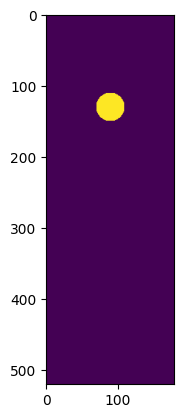

In [2]:
# lattice description
matrix = np.zeros((Nx,Ny, 9))
print(matrix.shape)

# obstruction description
# NOTE change this to take a png as an input for extra points
obstacle_mask = np.zeros((Nx,Ny), dtype=np.bool)
rr, cc = disk(CylinderCenter, CylinderRadius, shape=obstacle_mask.shape)
obstacle_mask[rr, cc] = True
plt.imshow(obstacle_mask)

In [11]:
# inlet flow
def u_inlet_x(y):
    """
    Intlet flow with a small introduced perturbation.
    """
    return U_lb * (1.0 + 1e-4*np.sin(y/(2*np.pi*(Ny-1))))

# velocity vector
velVectors = np.array([(x,y) for x in [0,-1,1] for y in [0,-1,1]])
Weights = np.array((4/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/9, 1/36, 1/36))
print(Weights)

def calc_ro(matrix):
    """
    Sum all distribution functions (directions) for each lattice cell.
    Formula: rho = sum(f_i)
    """
    # matrix shape is (Nx, Ny, 9), we sum over the last axis
    return np.sum(matrix, axis=2)

def calc_u(matrix, c):
    """
    Calculate the macroscopic velocity vector for each pixel.
    Formula: u = (1/rho) * sum(f_i * c_i)
    """
    rho = calc_ro(matrix)
    # Compute momentum: sum of (f_i * c_i) for each cell
    # np.tensordot multiplies the 9 directions in 'matrix' by the vectors in 'c'
    momentum = np.tensordot(matrix, c, axes=(2, 0)) # Result shape: (Nx, Ny, 2)
    
    # Divide momentum by density to get velocity[cite: 1]
    # We add np.newaxis to rho to broadcast (Nx, Ny) over the 2 velocity components
    return momentum / rho[..., np.newaxis]

def calc_feq(rho, u, c, weights):
    """
    Calculates the Equilibrium distribution for all 9 directions.
    Formula: feq_i = W_i * rho * [1 + 3(c_i.u) + 4.5(c_i.u)^2 - 1.5u^2]
    """
    # Calculate u^2 (dot product of velocity with itself)
    u_sq = np.sum(u**2, axis=2) # Result shape: (Nx, Ny)
    
    # Calculate dot product (c_i . u) for all 9 directions i
    # Result shape: (Nx, Ny, 9)[cite: 1]
    dot_product = np.tensordot(u, c, axes=(2, 1))
    
    # Apply the equilibrium formula[cite: 1]
    # We use broadcasting for weights (9,) and rho (Nx, Ny)
    term1 = 3.0 * dot_product
    term2 = 4.5 * (dot_product**2)
    term3 = 1.5 * u_sq[..., np.newaxis]
    
    feq = weights[np.newaxis, np.newaxis, :] * rho[..., np.newaxis] * (1.0 + term1 + term2 - term3)
    return feq


[0.44444444 0.11111111 0.11111111 0.11111111 0.02777778 0.02777778
 0.11111111 0.02777778 0.02777778]


In [ ]:
fin = matrix.copy()
fout = matrix.copy()

vel = np.fromfunction(lambda d,x,y: (1-d) * U_lb * (1.0 + 1e-6*np.sin(y/(Ly*2*np.pi))), (2,Nx,Ny))
print(vel.shape)
feq = 

(2, 520, 180)